## Confidence-Accuracy and Routing-Threshold Analysis

This notebook studies how **logistic regression confidence** relates to **correctness** on training data, then sweeps a **routing threshold** for the tiered pipeline (logistic regression when confident, LLM judge when not).

### Confidence-Accuracy Analysis

For each training row we obtain out-of-fold (OOF) logistic regression predictions grouped by `prompt_text`, then compute **routing confidence** via `lr_confidence` (same signal as production escalation in [`llm_hallucination_judge.py`](llm_hallucination_judge.py)). We bin confidence and compare **mean confidence** to **fraction correct** (reliability), and plot a **selective-prediction** curve: if we only accepted the highest-confidence predictions, how would accuracy change? These plots describe calibration and deferral tradeoffs; they do not assume probabilities are well-calibrated in the literal sense (balanced class weights can skew raw scores).

### Routing-Threshold Analysis

We simulate the tiered classifier on **train rows only**: if `should_escalate(lr_proba, lr_pred, t)` is false, use the OOF LR label; otherwise use a **cached NIM judge label** from [`judge_cache_dataset_v1.json`](../data/judge_cache_dataset_v1.json) (full dataset, no live API calls). We sweep a coarse grid of `t` and report F1, escalation rate, and related metrics.

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

from hallucination_features import FEATURE_COLS, build_augmented_lr_pipeline, light_clean
from llm_hallucination_judge import lr_confidence, should_escalate

In [2]:
RANDOM_STATE = 1
TEST_SIZE = 0.2
CV_FOLDS = 3
THRESHOLD_GRID = np.round(np.arange(0.55, 0.905, 0.05), 2)

DATA_DIR = Path.cwd() / "data"
if not (DATA_DIR / "llm_hallucination_dataset_v1.csv").is_file():
    DATA_DIR = Path.cwd().parent / "data"
DATASET_CSV = DATA_DIR / "llm_hallucination_dataset_v1.csv"
JUDGE_CACHE_PATH = DATA_DIR / "judge_cache_dataset_v1.json"

## Preprocessing

Load the hallucination dataset, clean response text, and split **by unique prompt** (20% of prompts held out; train rows used below for OOF scores and threshold grid).

In [3]:
# Modified by Cursor
llm_df = pd.read_csv(DATASET_CSV)
llm_df = llm_df.drop(columns=["notes"], errors="ignore")

llm_df["prompt_text"] = llm_df["prompt_text"].astype(str)
llm_df["response_text"] = llm_df["response_text"].astype(str)
llm_df["response_clean"] = llm_df["response_text"].map(light_clean)

unique_prompts = llm_df["prompt_text"].unique()
train_prompts, test_prompts = train_test_split(
    unique_prompts, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

train_mask = llm_df["prompt_text"].isin(train_prompts)
train_df = llm_df.loc[train_mask].reset_index(drop=True)

X_train = train_df[FEATURE_COLS]
y_train = train_df["hallucination_label"].astype(int)
groups_train = train_df["prompt_text"]

print(f"Rows: total={len(llm_df)}, train={len(train_df)}, test={len(llm_df) - len(train_df)}")
print(f"Unique prompts: train={train_prompts.size}, test={test_prompts.size}")

Rows: total=200, train=159, test=41
Unique prompts: train=42, test=11


## Confidence-Accuracy Calibration Analysis

OOF LR scores on train (grouped by prompt), then reliability bins and selective-prediction curves for routing confidence.

,bin_lo,bin_hi,n,mean_confidence,accuracy
0,0.505340,0.656517,31,0.577357,0.548387
1,0.656517,0.792811,32,0.741502,0.718750
2,0.792811,0.893287,31,0.830023,0.838710
3,0.893287,0.953725,33,0.919482,0.484848
4,0.953725,0.997364,32,0.982242,1.000000


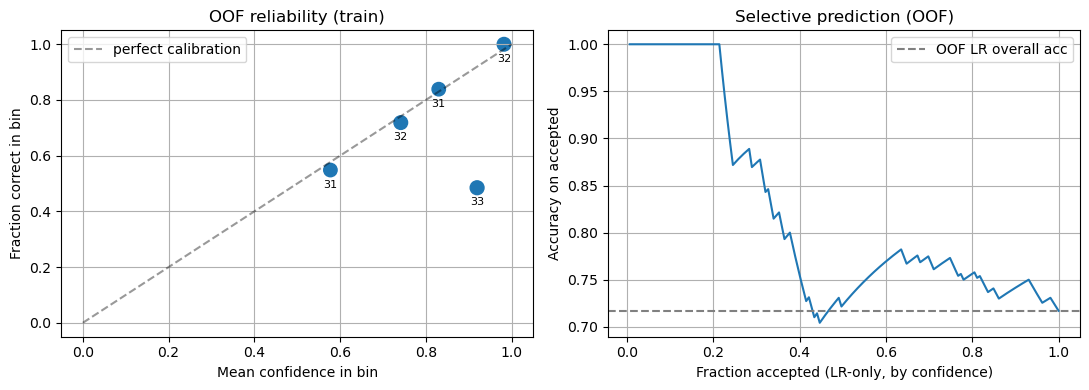

In [4]:
def compute_oof_lr(
    X: pd.DataFrame,
    y: pd.Series,
    groups: pd.Series,
    *,
    n_splits: int = CV_FOLDS,
    random_state: int = RANDOM_STATE,
) -> tuple[np.ndarray, np.ndarray]:
    cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    oof_proba = np.zeros((len(y), 2), dtype=float)
    oof_pred = np.zeros(len(y), dtype=int)
    fold_id = np.full(len(y), -1, dtype=int)

    for fold, (tr_idx, val_idx) in enumerate(cv.split(X, y, groups)):
        pipe = clone(build_augmented_lr_pipeline())
        pipe.fit(X.iloc[tr_idx], y.iloc[tr_idx])
        oof_proba[val_idx] = pipe.predict_proba(X.iloc[val_idx])
        oof_pred[val_idx] = pipe.predict(X.iloc[val_idx])
        fold_id[val_idx] = fold

    assert (fold_id >= 0).all(), "OOF fold assignment incomplete"
    return oof_proba, oof_pred


def reliability_by_bins(
    confidence: np.ndarray,
    correct: np.ndarray,
    *,
    n_bins: int = 5,
    method: str = "quantile",
) -> pd.DataFrame:
    conf = np.asarray(confidence, dtype=float)
    corr = np.asarray(correct, dtype=bool)
    if method == "quantile":
        edges = np.quantile(conf, np.linspace(0, 1, n_bins + 1))
        edges = np.unique(edges)
        if len(edges) < 3:
            edges = np.linspace(conf.min(), conf.max(), n_bins + 1)
    else:
        edges = np.linspace(conf.min(), conf.max(), n_bins + 1)

    rows = []
    for i in range(len(edges) - 1):
        lo, hi = edges[i], edges[i + 1]
        if i < len(edges) - 2:
            mask = (conf >= lo) & (conf < hi)
        else:
            mask = (conf >= lo) & (conf <= hi)
        n = int(mask.sum())
        if n == 0:
            continue
        rows.append(
            {
                "bin_lo": lo,
                "bin_hi": hi,
                "n": n,
                "mean_confidence": float(conf[mask].mean()),
                "accuracy": float(corr[mask].mean()),
            }
        )
    return pd.DataFrame(rows)


def selective_prediction_curve(
    confidence: np.ndarray,
    correct: np.ndarray,
) -> pd.DataFrame:
    order = np.argsort(-confidence)
    corr = correct[order]
    n = len(corr)
    frac = np.arange(1, n + 1) / n
    acc = np.cumsum(corr) / np.arange(1, n + 1)
    return pd.DataFrame({"fraction_accepted": frac, "accuracy_on_accepted": acc})


oof_proba, oof_pred = compute_oof_lr(X_train, y_train, groups_train)
oof_conf = np.array(
    [lr_confidence(oof_proba[i].tolist(), int(oof_pred[i])) for i in range(len(y_train))]
)
oof_correct = oof_pred == y_train.to_numpy()

rel_df = reliability_by_bins(oof_conf, oof_correct, n_bins=5, method="quantile")
display(rel_df)
if (rel_df["n"] < 5).any():
    print("Note: some reliability bins are sparse (n < 5); interpret qualitatively.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4, label="perfect calibration")
axes[0].scatter(rel_df["mean_confidence"], rel_df["accuracy"], s=rel_df["n"] * 3)
for _, row in rel_df.iterrows():
    axes[0].annotate(int(row["n"]), (row["mean_confidence"], row["accuracy"]), fontsize=8, xytext=(0, -7), textcoords="offset points", ha="center", va="top")
axes[0].set_xlabel("Mean confidence in bin")
axes[0].set_ylabel("Fraction correct in bin")
axes[0].set_title("OOF reliability (train)")
axes[0].grid()
axes[0].legend()

sel_df = selective_prediction_curve(oof_conf, oof_correct)
axes[1].plot(sel_df["fraction_accepted"], sel_df["accuracy_on_accepted"])
axes[1].axhline(oof_correct.mean(), color="gray", ls="--", label="OOF LR overall acc")
axes[1].set_xlabel("Fraction accepted (LR-only, by confidence)")
axes[1].set_ylabel("Accuracy on accepted")
axes[1].set_title("Selective prediction (OOF)")
axes[1].legend()
axes[1].grid()
plt.tight_layout()
plt.show()

## Routing Threshold Analysis

Tiered simulation on train OOF scores: accept LR when confidence ≥ `t`, else use judge labels from the precomputed cache (train `record_id`s only).

,threshold,f1,precision,recall,accuracy,escalation_rate,lr_only_acc_on_accepted,n_escalated
0,0.55,0.6667,0.6721,0.6613,0.7421,0.0503,0.7351,8
1,0.60,0.6833,0.7069,0.6613,0.7610,0.1195,0.7357,19
2,0.65,0.7193,0.7885,0.6613,0.7987,0.1950,0.7578,31
3,0.70,0.7207,0.8163,0.6452,0.8050,0.2390,0.7603,38
4,0.75,0.7222,0.8478,0.6290,0.8113,0.2830,0.7632,45
5,0.80,0.7255,0.9250,0.5968,0.8239,0.4277,0.7582,68
6,0.85,0.7255,0.9250,0.5968,0.8239,0.5409,0.7123,86
7,0.90,0.7963,0.9348,0.6935,0.8616,0.6352,0.7931,101


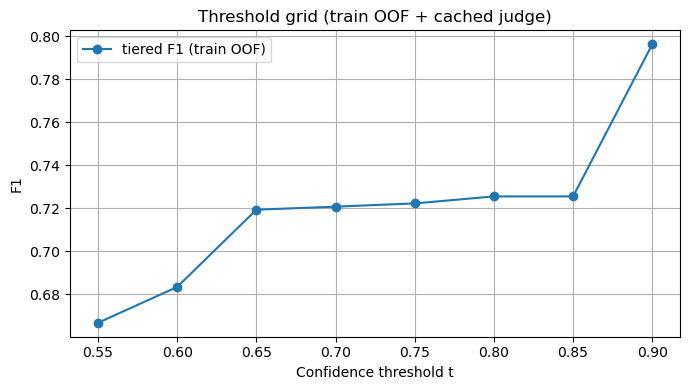

In [5]:
def load_judge_cache(path: Path) -> dict[str, dict]:
    with path.open(encoding="utf-8") as f:
        return json.load(f)


judge_cache = load_judge_cache(JUDGE_CACHE_PATH)
train_rids = [str(rid) for rid in train_df["record_id"]]
missing = [rid for rid in train_rids if rid not in judge_cache]
if missing:
    raise RuntimeError(
        f"{len(missing)} train record_id(s) missing from {JUDGE_CACHE_PATH}; "
        "run build_judge_cache_dataset.py or refresh the cache."
    )

train_judge_label = np.array(
    [int(judge_cache[rid]["hallucination_label"]) for rid in train_rids],
    dtype=int,
)

def tiered_predict(
    lr_pred: np.ndarray,
    lr_proba: np.ndarray,
    judge_labels: np.ndarray,
    threshold: float,
) -> tuple[np.ndarray, np.ndarray]:
    n = len(lr_pred)
    final = np.zeros(n, dtype=int)
    escalated = np.zeros(n, dtype=bool)
    for i in range(n):
        esc = should_escalate(lr_proba[i].tolist(), int(lr_pred[i]), threshold)
        escalated[i] = esc
        final[i] = int(judge_labels[i]) if esc else int(lr_pred[i])
    return final, escalated


def tiered_metrics(
    y_true: np.ndarray,
    lr_pred: np.ndarray,
    lr_proba: np.ndarray,
    judge_labels: np.ndarray,
    threshold: float,
) -> dict[str, float]:
    final, escalated = tiered_predict(lr_pred, lr_proba, judge_labels, threshold)
    accepted = ~escalated
    lr_only_acc = (
        float(accuracy_score(y_true[accepted], lr_pred[accepted])) if accepted.any() else float("nan")
    )
    return {
        "threshold": float(threshold),
        "f1": float(f1_score(y_true, final)),
        "precision": float(precision_score(y_true, final, zero_division=0)),
        "recall": float(recall_score(y_true, final, zero_division=0)),
        "accuracy": float(accuracy_score(y_true, final)),
        "escalation_rate": float(escalated.mean()),
        "lr_only_acc_on_accepted": lr_only_acc,
        "n_escalated": int(escalated.sum()),
    }


y_train_np = y_train.to_numpy()
grid_rows = [
    tiered_metrics(y_train_np, oof_pred, oof_proba, train_judge_label, float(t))
    for t in THRESHOLD_GRID
]
grid_df = pd.DataFrame(grid_rows).sort_values("threshold").reset_index(drop=True)
display(grid_df.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grid_df["threshold"], grid_df["f1"], marker="o", label="tiered F1 (train OOF)")
ax.set_xlabel("Confidence threshold t")
ax.set_ylabel("F1")
ax.set_title("Threshold grid (train OOF + cached judge)")
ax.legend()
ax.grid()
plt.tight_layout()
plt.show()